# Ariketa 5.4 — CNNen sarrera irudiekin 🖼️ (EGITEKO)

MLP batean `Flatten`-ek irudia bektore bihurtzen du; ondorengo Dense geruzek **ez dute berez auzokidetasun espaziala edo pisu partekatuak aprobetxatzen**. CNNek, berriz, kernel lokalak eta **weight sharing** erabiltzen dituzte. Gaur bi arkitekturak alderatuko ditugu.


> 🌐 **5072 ML LAB · CNN KERNEL EXPLORER**  
> Kernel 3×3 → feature map → ReLU → MaxPool prozesua pausoz pauso ikusteko.  
> **https://rbarrenago.github.io/5072-ml/demos/cnn-kernel-explorer/**


## 📝 Hiru modu

- 🟢 **KOMENTATU** · 🟡 **HUTSUNEAK BETE** (`____`) · 🔴 **KODETU ZEROTIK**

> 💡 Colab-en: *Exekuzio-ingurunea → GPU* azkarrago entrenatzeko.


## 0. Prestaketa 🟢 — digituak IRUDI gisa


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digituak = load_digits()
X = digituak.images.reshape(-1, 8, 8, 1) / 16.0  # (1797, 8, 8, 1), normalizatua [0,1]
y = digituak.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Irudi forma:', X_train.shape[1:], '| train/test:', len(X_train), len(X_test))  # (8, 8, 1) | 1437 360

Irudi forma: (8, 8, 1) | train/test: 1437 360


### a) Begiratu digitu batzuk 🟢


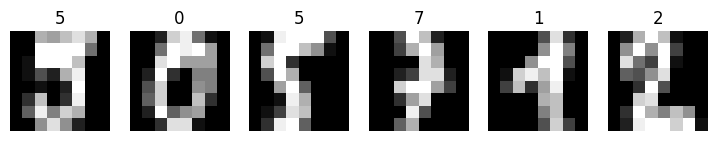

In [2]:
fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for i, ax in enumerate(axes):  # lehen 6 digituak
    ax.imshow(X_train[i].reshape(8, 8), cmap='gray'); ax.set_title(int(y_train[i])); ax.axis('off')
plt.show()  # 8x8 irudi txikiak

## 4.1 — Zergatik da CNN egokiagoa irudietarako? 💡

`Flatten`-ek **ez ditu pixel-balioak ezabatzen**: 8×8 matrizea 64 balioz osatutako bektore bihurtzen du. Arazoa da ondorengo Dense geruzek ez dutela irudien **lokalitatea** eta **pisuen partekatzea** arkitekturan txertatuta.

**Konboluzioak**, aldiz, kernel txiki bera irudi osoan zehar erabiltzen du, ertzak eta trazuak bezalako patroi lokalak detektatzeko.


### a) MLP (erreferentzia) 🟢


In [3]:
tf.keras.utils.set_random_seed(42)
mlp = keras.Sequential([
    layers.Input((8, 8, 1)),
    layers.Flatten(),  #
    layers.Dense(32, activation='relu'),
    layers.Dense(10, activation='softmax')
])
mlp.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
mlp.fit(X_train, y_train, epochs=30, verbose=0)
print('MLP (lautua) test acc:', round(mlp.evaluate(X_test, y_test, verbose=0)[1], 3), '| params:', mlp.count_params())


MLP (lautua) test acc: 0.956 | params: 2410


### b) CNN 🟡

`Conv2D` (iragazkiak) + `MaxPooling2D` (laburtu) + `Dense` (sailkatu).

**Hutsuneak bete:** iragazkiaren tamaina (3×3) eta pooling-aren tamaina (2).


In [7]:
tf.keras.utils.set_random_seed(42)
cnn = keras.Sequential([
    layers.Input((8, 8, 1)),
    layers.Conv2D(16, 3, activation='relu', padding='same'),  # bete: iragazki-tamaina (3)
    layers.MaxPooling2D(2),  # bete: pooling-tamaina (2)
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(10, activation='softmax')
])
cnn.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
cnn.fit(X_train, y_train, epochs=30, verbose=0)
print('CNN test acc:', round(cnn.evaluate(X_test, y_test, verbose=0)[1], 3), '| params:', cnn.count_params())

CNN test acc: 0.983 | params: 6090


## 4.2 — Alderaketa

Bi modeloen test accuracy-a eta parametro kopurua alderatuko ditugu. **Ez dugu suposatuko CNN beti hobea denik**: 8×8 dataset hau oso txikia da. CNNen abantaila arkitektonikoa askoz argiagoa da irudi handiagoetan, non lokalitatea eta weight sharing-a oso baliotsuak diren.


In [8]:
print('MLP test acc:', round(mlp.evaluate(X_test, y_test, verbose=0)[1], 3))  #
print('CNN test acc:', round(cnn.evaluate(X_test, y_test, verbose=0)[1], 3))  #

MLP test acc: 0.956
CNN test acc: 0.983


### Parametro kopuruari buruzko ohar garrantzitsua

8×8ko adibide txiki honetan gure CNNak **MLPak baino parametro gehiago ere izan ditzake**. Horrek ez du CNNaren ideia gezurtatzen: abantaila nagusia **kernel berak irudi osoko posizioetan pisuak partekatzea** da. Irudiaren tamaina handitu ahala, Dense sare baten lehen geruzaren parametro kopurua oso azkar hazten da.


## 4.3 — Zer ikusten du lehen Conv2D geruzak? 👁️

CNNaren lehen geruzak sortutako **feature map** batzuk bistaratuko ditugu. Kanal bakoitza ikasitako kernel desberdin baten erantzuna da.


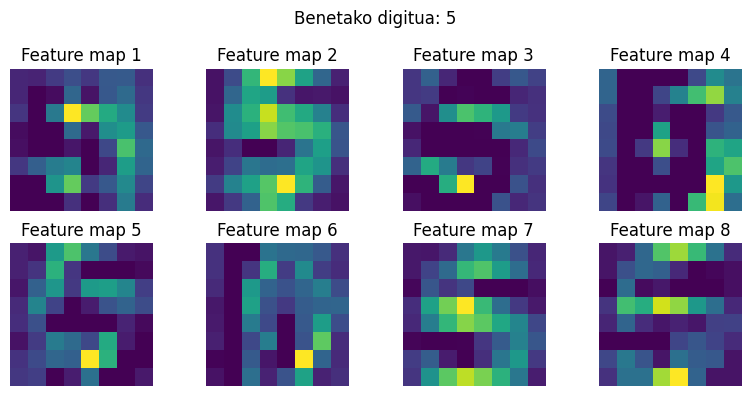

In [9]:
# Lehen Conv2D geruzaren aktibazioak
feature_model = keras.Model(inputs=cnn.inputs, outputs=cnn.layers[0].output)
mapak = feature_model.predict(X_test[:1], verbose=0)[0]

fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for k, ax in enumerate(axes.flat):
    ax.imshow(mapak[:, :, k], cmap='viridis')
    ax.set_title(f'Feature map {k+1}')
    ax.axis('off')
plt.suptitle(f'Benetako digitua: {y_test[0]}')
plt.tight_layout(); plt.show()


> **Colab-en probatu (aukerakoa): MNIST (28×28).** Kargatu `keras.datasets.mnist` eta aldatu sarrera `(28,28,1)`-era; logika **berdin-berdina** da. Internet behar da (Colab-en ez da arazoa) eta GPUak asko lagunduko dizu.


## 🧠 Gako-mezua

- **Konboluzioa** = kernel lokal bera irudiaren posizio askotan aplikatu (**weight sharing**).
- **Feature map** = kernel batek non erantzun duen erakusten duen mapa.
- **Pooling** = dimentsio espaziala murriztu → hurrengo geruzetan konputazio gutxiago.
- CNNak lokalitatea eta pisuen partekatzea arkitekturan txertatzen ditu; hori da MLParekiko alde nagusia.
- Entrenamenduaren motorra berdina da: **backprop-ek gradienteak kalkulatu; optimizatzaileak pisuak eguneratu**.

**Hurrengoan (S5):** noiz merezi du Deep Learning erabiltzea?


## Ondorioak

- `Flatten`-ek balioak mantentzen ditu, baina Dense sareak ez du lokalitatea berez aprobetxatzen.
- `Conv2D` + ReLU → feature map-ak; `MaxPooling2D` → dimentsio-murrizketa; Dense/Softmax → sailkapena.
- 8×8ko adibidean parametro kopuruak ez du zertan CNNaren alde egin; eskala handian weight sharing-aren abantaila nabarmenagoa da.
- Feature map-ak ikusteak “CNNak feature-ak ikasten ditu” esaldia konkretu bihurtzen du.
- Hurrengoa: **S5 — itxiera eta panorama**.
